In [2]:
import pandas as pd

In [3]:
df=pd.read_csv('../data/raw/PS_20174392719_1491204439457_log.csv')
print(df.shape)
print(df.head())
print(df.info())

(6362620, 11)
   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0             0.0        0               0  
1  M2044282225             0.0             0.0        0               0  
2   C553264065             0.0             0.0        1               0  
3    C38997010         21182.0             0.0        1               0  
4  M1230701703             0.0             0.0        0               0  
<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11

In [6]:
%pip install pandas

  Using cached pandas-3.0.6-cp312-cp312-win_amd64.whl.metadata (19 kB)
Using cached pandas-3.0.6-cp312-cp312-win_amd64.whl (9.7 MB)
Note: you may need to restart the kernel to use updated packages.


   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -----------------------------

In [4]:
print(df['isFraud'].value_counts())
print()
print(df['isFraud'].value_counts(normalize=True)*100)

isFraud
0    6354407
1       8213
Name: count, dtype: int64

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


In [5]:
print(df['type'].value_counts())

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


In [6]:
print(pd.crosstab(df['type'],df['isFraud'],normalize='index')*100)

isFraud            0         1
type                          
CASH_IN   100.000000  0.000000
CASH_OUT   99.816045  0.183955
DEBIT     100.000000  0.000000
PAYMENT   100.000000  0.000000
TRANSFER   99.231201  0.768799


In [7]:
print(df.isnull().sum())


step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [8]:
print(df.isnull().sum().sum())


0


In [9]:
print(df.groupby('isFraud')['amount'].agg(['count','mean','median','min','max']))

           count          mean     median   min          max
isFraud                                                     
0        6354407  1.781970e+05   74684.72  0.01  92445516.64
1           8213  1.467967e+06  441423.44  0.00  10000000.00


In [10]:
print(df.groupby('isFraud')[["oldbalanceOrg", "newbalanceOrig",
                           "oldbalanceDest", "newbalanceDest"]].mean())

         oldbalanceOrg  newbalanceOrig  oldbalanceDest  newbalanceDest
isFraud                                                               
0         8.328287e+05   855970.228109    1.101421e+06    1.224926e+06
1         1.649668e+06   192392.631836    5.442496e+05    1.279708e+06


In [11]:
fraud=df[df['isFraud']==1]
print(fraud['type'].value_counts())

type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64


In [12]:
df['balance_error_orig']=(
    df['oldbalanceOrg']-df['amount']-df['newbalanceOrig']
)
print(df['balance_error_orig'].describe())

count    6.362620e+06
mean    -2.010925e+05
std      6.066505e+05
min     -9.244552e+07
25%     -2.496411e+05
50%     -6.867726e+04
75%     -2.954230e+03
max      1.000000e-02
Name: balance_error_orig, dtype: float64


In [15]:
# absolute balance error
df['balance_error_orig']=(
    df['oldbalanceOrg']-df['amount']-df['newbalanceOrig']
).abs()

In [16]:
df['balance_error_ratio']=(
    df['balance_error_orig']/(df['oldbalanceOrg']+1)
)

In [18]:
df["orig_balance_change"] = (
    df["oldbalanceOrg"] - df["newbalanceOrig"]
)

In [21]:
print(
    df.groupby("isFraud")[
        ["balance_error_orig",
         "balance_error_ratio",
         "orig_balance_change"]
    ].median()
)

print(
    df.groupby("isFraud")[
        ["balance_error_orig",
         "balance_error_ratio",
         "orig_balance_change"]
    ].mean()
)

print(
    df.groupby(["type", "isFraud"])["amount"]
      .median()
)

         balance_error_orig  balance_error_ratio  orig_balance_change
isFraud                                                              
0                  69049.31             7.079694                 0.00
1                      0.00             0.000000            436317.49
         balance_error_orig  balance_error_ratio  orig_balance_change
isFraud                                                              
0             201338.558304         71149.558456        -2.314152e+04
1              10692.325265          1160.980733         1.457275e+06
type      isFraud
CASH_IN   0          143427.710
CASH_OUT  0          146946.560
          1          435516.905
DEBIT     0            3048.990
PAYMENT   0            9482.190
TRANSFER  0          486521.910
          1          445705.760
Name: amount, dtype: float64


In [23]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.66.1-cp312-cp312-win_amd64.whl.metadata (132 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.66.1-cp312-cp312-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl (70 kB)

   -------- ------------------------------- 1/5 [fonttools]
   -------- ------------------------------- 1/5 [fonttools]
   -------- ------------------------------- 1/5 [fonttools]
   -------- ------------------------------- 1/5 [fonttools]
   -------- ------------------------------- 1/5 [fonttools]
   -------- --------

In [27]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


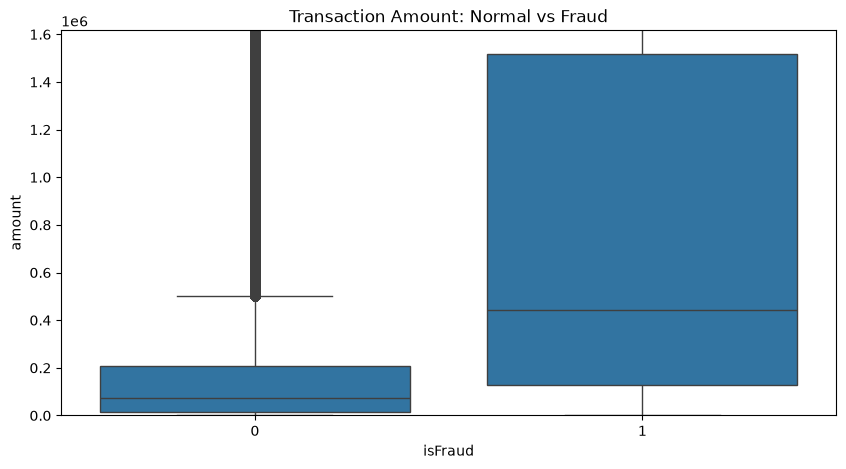

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,5))
sns.boxplot(
    data=df,
    x='isFraud',
    y='amount'
)
plt.ylim(0,df['amount'].quantile(0.99))
plt.title("Transaction Amount: Normal vs Fraud")
plt.show()

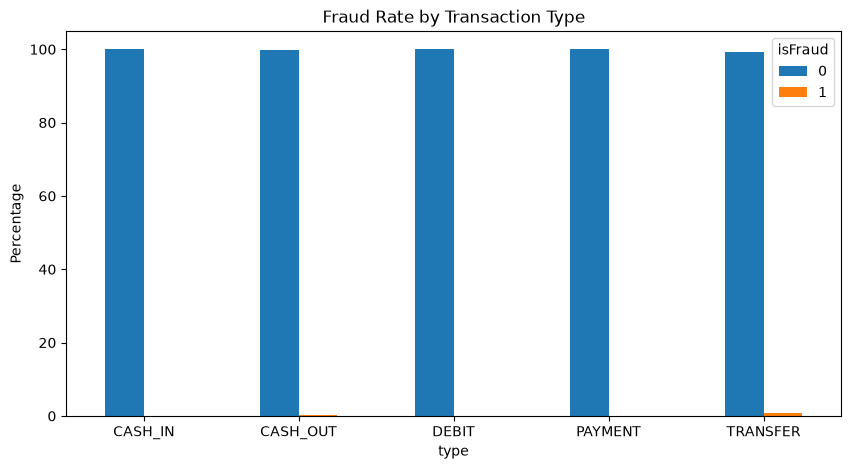

In [29]:
fraud_by_type = pd.crosstab(
    df["type"],
    df["isFraud"],
    normalize="index"
) * 100

fraud_by_type.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("Percentage")
plt.title("Fraud Rate by Transaction Type")
plt.xticks(rotation=0)
plt.show()

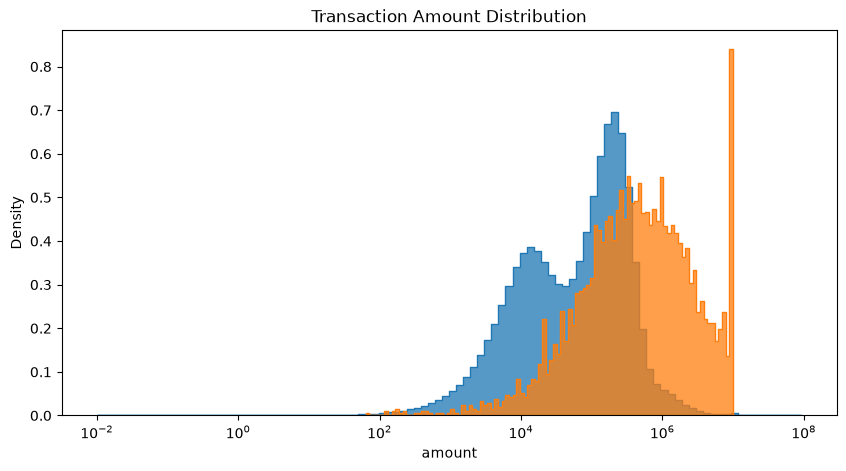

In [30]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df["isFraud"] == 0],
    x="amount",
    bins=100,
    log_scale=True,
    stat="density",
    element="step"
)

sns.histplot(
    data=df[df["isFraud"] == 1],
    x="amount",
    bins=100,
    log_scale=True,
    stat="density",
    element="step"
)

plt.title("Transaction Amount Distribution")
plt.show()

In [32]:
fraud_rate = (
    df.groupby("type")["isFraud"]
      .mean()
      .sort_values(ascending=False)
      * 100
)

print(fraud_rate)

print(
    df.groupby("isFraud")[[
        "amount",
        "oldbalanceOrg",
        "newbalanceOrig",
        "oldbalanceDest",
        "newbalanceDest"
    ]].median()
)

type
TRANSFER    0.768799
CASH_OUT    0.183955
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
Name: isFraud, dtype: float64
            amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
isFraud                                                             
0         74684.72       14069.00             0.0        133311.8   
1        441423.44      438983.45             0.0             0.0   

         newbalanceDest  
isFraud                  
0             214881.70  
1               4676.42  


In [36]:
df["orig_balance_change"] = (
    df["oldbalanceOrg"] - df["newbalanceOrig"]
)

df["dest_balance_change"] = (
    df["newbalanceDest"] - df["oldbalanceDest"]
)

df["orig_amount_error"] = (
    df["oldbalanceOrg"]
    - df["amount"]
    - df["newbalanceOrig"]
).abs()

df["dest_amount_error"] = (
    df["oldbalanceDest"]
    + df["amount"]
    - df["newbalanceDest"]
).abs()

In [38]:
features = [
    "amount",
    "orig_balance_change",
    "dest_balance_change",
    "orig_amount_error",
    "dest_amount_error"
]

print(
    df.groupby("isFraud")[features]
      .median()
)

print(
    df.groupby("isFraud")[features]
      .mean()
)

            amount  orig_balance_change  dest_balance_change  \
isFraud                                                        
0         74684.72                 0.00                  0.0   
1        441423.44            436317.49                  0.0   

         orig_amount_error  dest_amount_error  
isFraud                                        
0                 69049.31            5123.10  
1                     0.00            9511.69  
               amount  orig_balance_change  dest_balance_change  \
isFraud                                                           
0        1.781970e+05        -2.314152e+04        123504.809994   
1        1.467967e+06         1.457275e+06        735457.998071   

         orig_amount_error  dest_amount_error  
isFraud                                        
0            201338.558304       92756.964361  
1             10692.325265      745138.585637  
